In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from functions.new_variables import *
from functions.ensembles import *
from scipy.stats import skew, shapiro

In [2]:
dataset = pd.read_excel('../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../Codificação variaveis.xlsx')

In [3]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
relevant_variables = ['PERSON_ID', 'EBC', 'pT', 'cT']
numerical_variables = ['Age', 'Ki67 positive cells (%) at CB']
categorical_variables = ['N (Regional nodes affected)', 'Number identifying the lesion in the patient', 
                         'Side location of the lesion', 'Classification with respect to other lesions', 
                         'Source of referral', 'Type of invasion at CB', 'Isotype at CB', 
                         'Oestrogen receptor status at CB', 'Progesterone receptor status at CB', 
                         'Disease extent', 'Grade at CB', 'Her2 overexpression (with immunohystochemistry) at CB']

In [4]:
#correcting th error in the column name
dataset.rename(columns={'Istotype at CB': 'Isotype at CB'}, inplace=True)

In [5]:
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

In [6]:
dataset = dataset[dataset['Final recommendations to patient'] == 4]

In [7]:
#remover os pT e os ct que não estão anotados
dataset = dataset[dataset['pT'].notna()]
dataset = dataset[dataset['T by imaging or clinical examination'] != 'X']
dataset.reset_index(drop=True, inplace=True)

In [9]:
dataset['T by imaging or clinical examination'].value_counts()

T by imaging or clinical examination
2     832
1c    281
3     188
1b     33
4b     26
Is     18
1      18
4d     14
4      11
0       3
1a      3
4a      3
4c      1
Name: count, dtype: int64

In [8]:
dataset['pT'].value_counts()

pT
0       389
1C      323
2       302
1B      152
IS       91
1A       91
3        66
1MIC      7
4B        5
1         2
4D        2
4C        1
Name: count, dtype: int64

In [64]:
response(dataset, 'T by imaging or clinical examination', 'pT')

Done


In [65]:
#since the clinical staging uses the nodes
node = ['N (Regional nodes affected)']
fill_with_mode(dataset, node)
cT(dataset)
clinical_staging (dataset)

# pT was already loaded
# e vou cagar na variavel do cT fica só o outro T by imaging or clinical examination
new_variables = ['Cancer stage']
categorical_variables = categorical_variables + new_variables

In [66]:
change_to_numeric(dataset, numerical_variables)
change_to_categorical(dataset, categorical_variables)

Done
Done


In [67]:
columns_to_map = {
    'N (Regional nodes affected)': {0: 0, 1: 1, 2: 2_3, 3: 2_3},
    'Side location of the lesion': {'L': 0, 'R': 1},
    'Source of referral': {1: 0, 2: 1},
    'Type of invasion at CB': {1: 0, 2: 1},
    'Oestrogen receptor status at CB': {1: 0, 2: 1},
    'Progesterone receptor status at CB': {1: 0, 2: 1},
    'Number identifying the lesion in the patient': {1: 1, 2: 0, 3: 0, 4: 0},
    'Isotype at CB': {1: 1, 2: 2, 3: 4, 4: 4},
    'Disease extent': {0: 0, 1: 1, 2: 1}
}

for column, mapping in columns_to_map.items():
    dataset[column] = dataset[column].map(mapping)

In [68]:
# Replace missing values in the specified columns
mode_variables = ['Side location of the lesion', 'Classification with respect to other lesions', 'Type of invasion at CB', 'Disease extent', 
                'Oestrogen receptor status at CB', 'Cancer stage', 'Isotype at CB', 'Progesterone receptor status at CB', 
                'Grade at CB', 'Her2 overexpression (with immunohystochemistry) at CB']
fill_with_mode(dataset, mode_variables)

'Done'

In [69]:
ki67 = ['Ki67 positive cells (%) at CB']
median_imputer(dataset, ki67)

'Done'

In [70]:
one_hot_variables = ['N (Regional nodes affected)', 'Classification with respect to other lesions', 'Isotype at CB', 'Cancer stage', 'Grade at CB', 'Her2 overexpression (with immunohystochemistry) at CB']
ohe_dataset, new_column_names = one_hot_encoding(dataset, one_hot_variables, drop_first=None)

In [71]:
categorical_variables = [col for col in categorical_variables if col not in one_hot_variables]
categorical_variables.extend(new_column_names.tolist())

selected_variables = relevant_variables + numerical_variables + categorical_variables

In [72]:
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Endocrine therapy performed']

dataset = ohe_dataset

In [73]:
numerical_data, categorical_data = type_separation(data_code, treatment_variables)
len(numerical_data), len(categorical_data)

(3, 10)

In [74]:
replace_missing_values(dataset, numerical_data, 0)

Done


In [75]:
dataset.drop(index=0, inplace=True)
dataset.reset_index(inplace=True, drop=True)
replace_missing_values(dataset, categorical_data, 0)

Done


In [76]:
variable_two_to_zero = ['Adjuvant chemotherapy', 'Chemotherapy performed', 'Endocrine therapy performed']
variable_two_to_one = ['Adjuvant therapy with biological drugs']

two_to_zero(dataset, variable_two_to_zero)
two_to_one(dataset, variable_two_to_one)

'Done'

In [77]:
to_remove = ['PERSON_ID', 'EBC', 'cT', 'pT']
important_variables = ['PERSON_ID', 'Neoadjuvant Response']
diagnosis_variables = [col for col in selected_variables if col not in to_remove]
selected_columns = important_variables + treatment_variables + diagnosis_variables

In [78]:
survival_dataset = dataset[selected_columns]

In [79]:
# Check if there are any NaN values in the dataset
contains_nan = survival_dataset.isnull().any().any()
print("Does survival_dataset contain NaN values?", contains_nan)

# Optionally, to see which columns contain NaN values
nan_columns = survival_dataset.columns[survival_dataset.isnull().any()].tolist()
print("Columns with NaN values:", nan_columns)

Does survival_dataset contain NaN values? False
Columns with NaN values: []


In [80]:
survival_dataset.to_csv("data.csv")

In [81]:
with open("diagnosis.txt", "w") as file:
    for item in diagnosis_variables:
        file.write(str(item) + "\n")
with open("treatment.txt", "w") as file:
    for item in treatment_variables:
        file.write(str(item) + "\n")

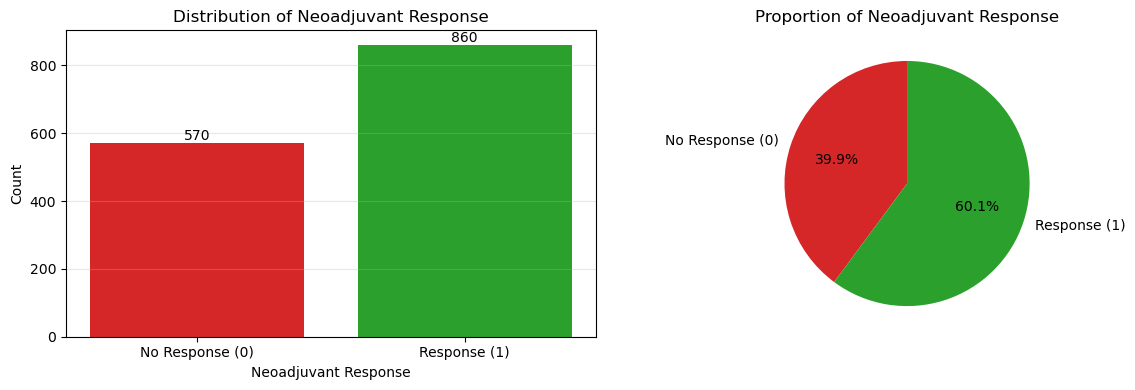


Neoadjuvant Response Summary:
Total patients: 1430
No Response (0): 570 (39.86%)
Response (1): 860 (60.14%)


In [83]:
# Create visualizations for the distribution of Neoadjuvant Response
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
response_counts = survival_dataset['Neoadjuvant Response'].value_counts().sort_index()
axes[0].bar(response_counts.index, response_counts.values, color=['#d62728', '#2ca02c'])
axes[0].set_xlabel('Neoadjuvant Response')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Neoadjuvant Response')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Response (0)', 'Response (1)'])
axes[0].grid(axis='y', alpha=0.3)

# Add count labels on bars
for i, (idx, count) in enumerate(response_counts.items()):
    axes[0].text(idx, count, str(count), ha='center', va='bottom')

# Pie chart
axes[1].pie(response_counts.values, labels=['No Response (0)', 'Response (1)'], 
            autopct='%1.1f%%', startangle=90, colors=['#d62728', '#2ca02c'])
axes[1].set_title('Proportion of Neoadjuvant Response')

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nNeoadjuvant Response Summary:")
print(f"Total patients: {len(survival_dataset)}")
print(f"No Response (0): {response_counts.get(0, 0)} ({response_counts.get(0, 0)/len(survival_dataset)*100:.2f}%)")
print(f"Response (1): {response_counts.get(1, 0)} ({response_counts.get(1, 0)/len(survival_dataset)*100:.2f}%)")

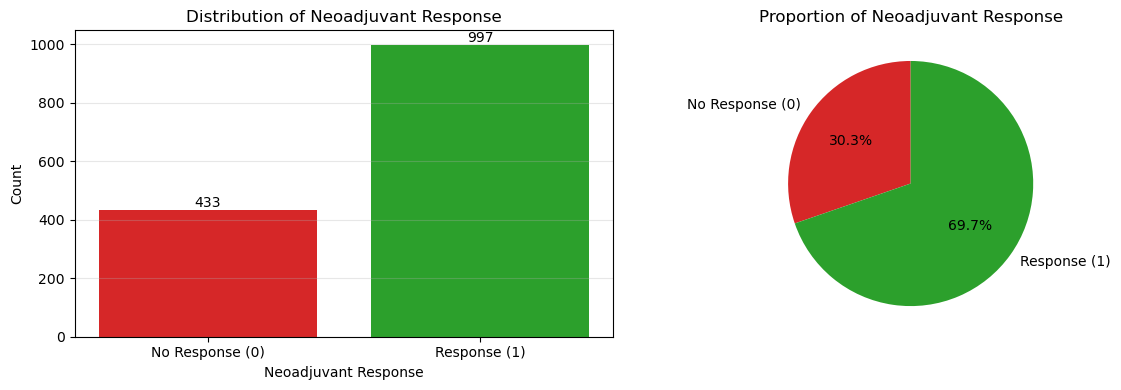


Neoadjuvant Response Summary:
Total patients: 1430
No Response (0): 433 (30.28%)
Response (1): 997 (69.72%)


In [157]:
# Create visualizations for the distribution of Neoadjuvant Response
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
response_counts = survival_dataset['Neoadjuvant Response'].value_counts().sort_index()
axes[0].bar(response_counts.index, response_counts.values, color=['#d62728', '#2ca02c'])
axes[0].set_xlabel('Neoadjuvant Response')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Neoadjuvant Response')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Response (0)', 'Response (1)'])
axes[0].grid(axis='y', alpha=0.3)

# Add count labels on bars
for i, (idx, count) in enumerate(response_counts.items()):
    axes[0].text(idx, count, str(count), ha='center', va='bottom')

# Pie chart
axes[1].pie(response_counts.values, labels=['No Response (0)', 'Response (1)'], 
            autopct='%1.1f%%', startangle=90, colors=['#d62728', '#2ca02c'])
axes[1].set_title('Proportion of Neoadjuvant Response')

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nNeoadjuvant Response Summary:")
print(f"Total patients: {len(survival_dataset)}")
print(f"No Response (0): {response_counts.get(0, 0)} ({response_counts.get(0, 0)/len(survival_dataset)*100:.2f}%)")
print(f"Response (1): {response_counts.get(1, 0)} ({response_counts.get(1, 0)/len(survival_dataset)*100:.2f}%)")